# Análisis del rendimiento académico con MongoDB y Python

**Proyecto Final – Bases de Datos para IA (ITQ)** · Autores: Edgar Ulloa, Freddy Guevara y Edgar Crespo

Este notebook se conecta a la base `academica` de MongoDB, ejecuta seis
consultas de agregación y presenta los indicadores con tablas y gráficos.

| Regla del curso | Valor |
|---|---|
| Nota mínima para aprobar | 7 sobre 10 |
| Asistencia mínima | 70 % |
| Nota final | 3 parciales de 2,2 puntos + proyecto final de 3,4 |

**Cómo ejecutarlo en VS Code:** abre MongoDB (Compass conectado), elige el
kernel de Python arriba a la derecha y pulsa **Run All**.

## 1. Librerías y configuración

In [1]:
import os
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display
from pymongo import MongoClient
from pymongo.database import Database

MONGO_URI = os.getenv("MONGO_URI", "mongodb://localhost:27017")
NOMBRE_BD = os.getenv("MONGO_DB", "academica")
CARPETA_GRAFICOS = Path("graficos")
CARPETA_GRAFICOS.mkdir(exist_ok=True)

NOTA_MINIMA = 7.0
ASISTENCIA_MINIMA = 70.0

# Paleta: un color principal, uno de contraste y tintas neutras para texto
COLOR_PRINCIPAL = "#2a78d6"   # azul
COLOR_CONTRASTE = "#eb6834"   # naranja
COLOR_REFERENCIA = "#8a8984"  # gris para lineas de umbral
TINTA_PRIMARIA = "#0b0b0b"
TINTA_SECUNDARIA = "#52514e"
COLOR_GRILLA = "#e4e3df"
FONDO = "#fcfcfb"

## 2. Conexión con MongoDB

Se abre la conexión y se verifica que las cuatro colecciones tengan los
documentos esperados: 120 estudiantes, 5 asignaturas, 600 calificaciones y
4 560 registros de asistencia.

In [2]:
def conectar_bd(uri=MONGO_URI, nombre_bd=NOMBRE_BD):
    """Abre la conexion con MongoDB y devuelve la base de datos.

    Args:
        uri: Cadena de conexion de MongoDB.
        nombre_bd: Nombre de la base de datos a usar.

    Returns:
        Objeto ``Database`` de pymongo.

    Raises:
        pymongo.errors.ServerSelectionTimeoutError: Si el servidor no
            responde en 5 segundos.
    """
    cliente = MongoClient(uri, serverSelectionTimeoutMS=5000)
    cliente.admin.command("ping")  # falla rapido si no hay servidor
    return cliente[nombre_bd]


def consultar(bd: Database, coleccion, pipeline):
    """Ejecuta un pipeline de agregacion y devuelve un DataFrame.

    Args:
        bd: Base de datos de MongoDB.
        coleccion: Nombre de la coleccion sobre la que se agrega.
        pipeline: Lista de etapas de agregacion.

    Returns:
        ``pandas.DataFrame`` con un documento por fila.
    """
    return pd.DataFrame(list(bd[coleccion].aggregate(pipeline)))

In [4]:
try:
    bd = conectar_bd()
    for coleccion in ["estudiantes", "asignaturas", "calificaciones",
                      "asistencia"]:
        print(f"{coleccion:15} {bd[coleccion].count_documents({}):>6} "
              "documentos")
except Exception as error:
    print("No se pudo conectar a MongoDB. Abre Compass y verifica que el "
          f"servidor este activo.\nDetalle: {error}")

estudiantes        120 documentos
asignaturas          5 documentos
calificaciones     600 documentos
asistencia        4560 documentos


## 3. Estilo de los gráficos

Funciones comunes: estilo sobrio, guardado en PNG y etiquetas de valor.

In [5]:
def configurar_estilo():
    """Aplica un estilo sobrio y comun a todos los graficos."""
    plt.rcParams.update({
        "figure.facecolor": FONDO,
        "axes.facecolor": FONDO,
        "axes.edgecolor": COLOR_GRILLA,
        "axes.labelcolor": TINTA_SECUNDARIA,
        "axes.titlecolor": TINTA_PRIMARIA,
        "axes.titlesize": 13,
        "axes.titleweight": "bold",
        "axes.titlelocation": "left",
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": True,
        "axes.axisbelow": True,  # la grilla queda detras de las barras
        "grid.color": COLOR_GRILLA,
        "grid.linewidth": 0.8,
        "xtick.color": TINTA_SECUNDARIA,
        "ytick.color": TINTA_SECUNDARIA,
        "font.size": 10,
        "legend.frameon": False,
    })


def guardar(figura, nombre):
    """Guarda la figura como PNG y la muestra debajo de la celda.

    Args:
        figura: Figura de matplotlib.
        nombre: Nombre del archivo sin extension.

    Returns:
        Ruta del archivo generado.
    """
    ruta = CARPETA_GRAFICOS / f"{nombre}.png"
    figura.tight_layout()
    figura.savefig(ruta, dpi=150)
    plt.show()
    return ruta


def etiquetar_barras(eje, barras, formato="{:.1f}"):
    """Escribe el valor de cada barra al final de la misma.

    Args:
        eje: Eje de matplotlib que contiene las barras.
        barras: Contenedor devuelto por ``barh``.
        formato: Formato de texto para el valor.
    """
    for barra in barras:
        ancho = barra.get_width()
        eje.text(ancho, barra.get_y() + barra.get_height() / 2,
                 " " + formato.format(ancho), va="center",
                 color=TINTA_PRIMARIA, fontsize=9)


configurar_estilo()

## 4. Consulta 1 – Rendimiento por materia

Agrupa las calificaciones por asignatura (`$group`) y trae el nombre con
`$lookup`. Calcula promedio, asistencia y tasa de aprobación.

In [6]:
def rendimiento_por_materia(bd):
    """Consulta 1: promedio, asistencia y tasa de aprobacion por materia.

    Usa ``$lookup`` para traer el nombre de la asignatura.

    Args:
        bd: Base de datos de MongoDB.

    Returns:
        DataFrame ordenado de menor a mayor promedio.
    """
    pipeline = [
        {"$group": {
            "_id": "$codigo_asignatura",
            "promedio": {"$avg": "$nota_final"},
            "asistencia": {"$avg": "$porcentaje_asistencia"},
            "aprobados": {"$sum": {
                "$cond": [{"$eq": ["$estado", "APROBADO"]}, 1, 0]}},
            "total": {"$sum": 1},
        }},
        {"$lookup": {"from": "asignaturas", "localField": "_id",
                     "foreignField": "_id", "as": "asig"}},
        {"$unwind": "$asig"},
        {"$project": {"_id": 0, "materia": "$asig.nombre", "promedio": 1,
                      "asistencia": 1, "aprobados": 1, "total": 1}},
    ]
    datos = consultar(bd, "calificaciones", pipeline)
    datos["tasa_aprobacion"] = datos["aprobados"] / datos["total"] * 100
    columnas = ["materia", "promedio", "asistencia", "aprobados",
                "tasa_aprobacion"]
    return (datos[columnas].round(2)
            .sort_values("promedio").reset_index(drop=True))


def graficar_rendimiento_materia(datos):
    """Barras horizontales con la tasa de aprobacion por materia.

    Args:
        datos: Resultado de ``rendimiento_por_materia``.

    Returns:
        Ruta del PNG generado.
    """
    datos = datos.sort_values("tasa_aprobacion")
    figura, eje = plt.subplots(figsize=(8, 4))
    barras = eje.barh(datos["materia"], datos["tasa_aprobacion"],
                      color=COLOR_PRINCIPAL, height=0.6)
    etiquetar_barras(eje, barras, "{:.1f} %")
    eje.set_xlim(0, 100)
    eje.set_xlabel("Estudiantes aprobados (%)")
    eje.grid(axis="y", visible=False)
    eje.set_title("Tasa de aprobación por materia")
    return guardar(figura, "1_aprobacion_por_materia")

,materia,promedio,asistencia,aprobados,tasa_aprobacion
0,Matematicas para IA,7.38,85.59,74,61.67
1,Estadistica Aplicada,7.68,85.73,85,70.83
2,Bases de Datos,7.75,84.64,83,69.17
3,Programacion con Python,7.91,83.23,84,70.00
4,Ingles Tecnico,8.42,87.60,101,84.17


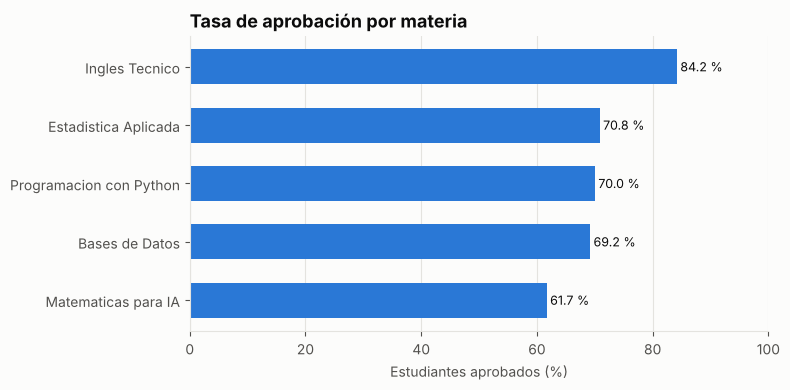

PosixPath('graficos/1_aprobacion_por_materia.png')

In [7]:
resultado_1 = rendimiento_por_materia(bd)
display(resultado_1.head(10))
graficar_rendimiento_materia(resultado_1)

## 5. Consulta 2 – Motivos de reprobación

Filtra los reprobados (`$match`) y los agrupa por motivo: nota,
asistencia o ambos.

In [8]:
def motivos_reprobacion(bd):
    """Consulta 2: numero de reprobaciones segun su motivo.

    Args:
        bd: Base de datos de MongoDB.

    Returns:
        DataFrame con columnas ``motivo`` y ``casos``.
    """
    pipeline = [
        {"$match": {"estado": "REPROBADO"}},
        {"$group": {"_id": "$motivo_reprobacion", "casos": {"$sum": 1}}},
        {"$sort": {"casos": -1}},
    ]
    datos = consultar(bd, "calificaciones", pipeline)
    nombres = {
        ("NOTA",): "Solo nota",
        ("ASISTENCIA",): "Solo asistencia",
        ("NOTA", "ASISTENCIA"): "Nota y asistencia",
    }
    datos["motivo"] = datos["_id"].apply(lambda m: nombres[tuple(m)])
    return datos[["motivo", "casos"]]


def graficar_motivos(datos):
    """Barras horizontales con las reprobaciones por motivo.

    Args:
        datos: Resultado de ``motivos_reprobacion``.

    Returns:
        Ruta del PNG generado.
    """
    datos = datos.sort_values("casos")
    figura, eje = plt.subplots(figsize=(8, 3.2))
    barras = eje.barh(datos["motivo"], datos["casos"],
                      color=COLOR_PRINCIPAL, height=0.6)
    etiquetar_barras(eje, barras, "{:.0f}")
    eje.set_xlabel("Registros reprobados")
    eje.grid(axis="y", visible=False)
    eje.set_title(f"Motivos de reprobación ({datos['casos'].sum()} casos)")
    return guardar(figura, "2_motivos_reprobacion")

,motivo,casos
0,Solo nota,100
1,Nota y asistencia,42
2,Solo asistencia,31


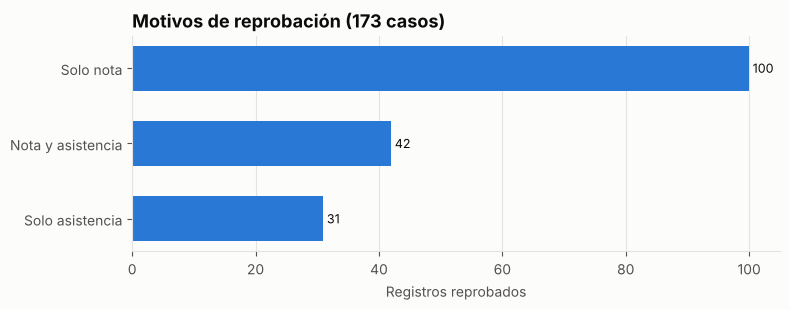

PosixPath('graficos/2_motivos_reprobacion.png')

In [9]:
resultado_2 = motivos_reprobacion(bd)
display(resultado_2.head(10))
graficar_motivos(resultado_2)

## 6. Consulta 3 – ¿Trabajar afecta el rendimiento?

Une calificaciones con estudiantes (`$lookup` + `$unwind`) y agrupa por dos
campos. `$addToSet` cuenta estudiantes únicos, porque cada uno tiene cinco
registros.

In [10]:
def rendimiento_por_perfil(bd):
    """Consulta 3: reprobacion segun si el estudiante trabaja y su jornada.

    Une ``calificaciones`` con ``estudiantes`` y cuenta estudiantes unicos
    con ``$addToSet``, porque cada estudiante tiene cinco registros.

    Args:
        bd: Base de datos de MongoDB.

    Returns:
        DataFrame con un grupo por combinacion de trabajo y jornada.
    """
    pipeline = [
        {"$lookup": {"from": "estudiantes", "localField": "id_estudiante",
                     "foreignField": "_id", "as": "est"}},
        {"$unwind": "$est"},
        {"$group": {
            "_id": {"trabaja": "$est.trabaja", "jornada": "$est.jornada"},
            "estudiantes": {"$addToSet": "$id_estudiante"},
            "promedio": {"$avg": "$nota_final"},
            "reprobados": {"$sum": {
                "$cond": [{"$eq": ["$estado", "REPROBADO"]}, 1, 0]}},
            "registros": {"$sum": 1},
        }},
    ]
    datos = consultar(bd, "calificaciones", pipeline)
    datos["perfil"] = datos["_id"].apply(
        lambda g: ("Trabaja" if g["trabaja"] else "No trabaja")
        + " · " + g["jornada"].capitalize()
    )
    datos["num_estudiantes"] = datos["estudiantes"].apply(len)
    datos["pct_reprobacion"] = datos["reprobados"] / datos["registros"] * 100
    columnas = ["perfil", "num_estudiantes", "promedio", "pct_reprobacion"]
    return (datos[columnas].round(2)
            .sort_values("pct_reprobacion").reset_index(drop=True))


def graficar_perfil(datos):
    """Barras horizontales con el % de reprobacion por perfil.

    Args:
        datos: Resultado de ``rendimiento_por_perfil``.

    Returns:
        Ruta del PNG generado.
    """
    etiquetas = [f"{p}  (n={n})" for p, n
                 in zip(datos["perfil"], datos["num_estudiantes"])]
    figura, eje = plt.subplots(figsize=(8, 3.5))
    barras = eje.barh(etiquetas, datos["pct_reprobacion"],
                      color=COLOR_PRINCIPAL, height=0.6)
    etiquetar_barras(eje, barras, "{:.1f} %")
    eje.set_xlabel("Registros reprobados (%)")
    eje.grid(axis="y", visible=False)
    eje.set_title("Reprobación según trabajo y jornada")
    return guardar(figura, "3_reprobacion_por_perfil")

,perfil,num_estudiantes,promedio,pct_reprobacion
0,Trabaja · Matutina,14,8.16,22.86
1,Trabaja · Nocturna,39,8.00,25.13
2,No trabaja · Nocturna,18,7.45,30.00
3,No trabaja · Matutina,49,7.73,33.06


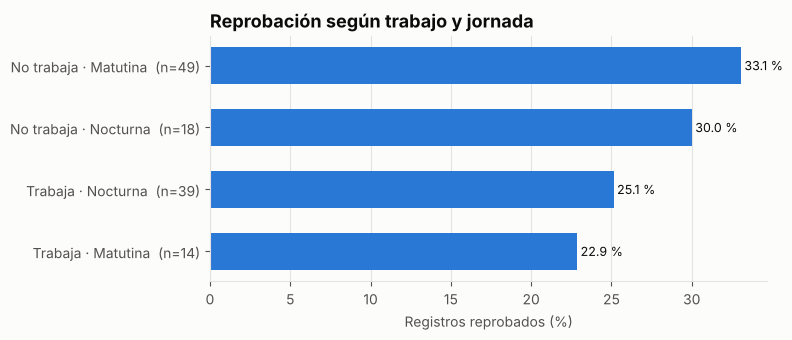

PosixPath('graficos/3_reprobacion_por_perfil.png')

In [11]:
resultado_3 = rendimiento_por_perfil(bd)
display(resultado_3.head(10))
graficar_perfil(resultado_3)

## 7. Consulta 4 – Estudiantes en riesgo

Doble `$group`: primero cuenta las materias reprobadas de cada estudiante y
luego cuántos estudiantes hay por cada conteo. En riesgo: 3 materias o más.

In [12]:
def materias_reprobadas_por_estudiante(bd):
    """Consulta 4: cuantos estudiantes reprobaron 0, 1, ... 5 materias.

    Primero cuenta reprobaciones por estudiante y luego agrupa ese conteo.

    Args:
        bd: Base de datos de MongoDB.

    Returns:
        DataFrame con columnas ``materias_reprobadas`` y ``estudiantes``.
    """
    pipeline = [
        {"$group": {
            "_id": "$id_estudiante",
            "reprobadas": {"$sum": {
                "$cond": [{"$eq": ["$estado", "REPROBADO"]}, 1, 0]}},
        }},
        {"$group": {"_id": "$reprobadas", "estudiantes": {"$sum": 1}}},
        {"$sort": {"_id": 1}},
    ]
    datos = consultar(bd, "calificaciones", pipeline)
    datos = datos.rename(columns={"_id": "materias_reprobadas"})
    return datos[["materias_reprobadas", "estudiantes"]]


def graficar_riesgo(datos):
    """Columnas con el numero de estudiantes segun materias reprobadas.

    Las columnas de 3 o mas materias (riesgo academico) se resaltan.

    Args:
        datos: Resultado de ``materias_reprobadas_por_estudiante``.

    Returns:
        Ruta del PNG generado.
    """
    colores = [COLOR_CONTRASTE if n >= 3 else COLOR_PRINCIPAL
               for n in datos["materias_reprobadas"]]
    figura, eje = plt.subplots(figsize=(8, 4))
    barras = eje.bar(datos["materias_reprobadas"].astype(str),
                     datos["estudiantes"], color=colores, width=0.6)
    for barra in barras:
        alto = barra.get_height()
        eje.text(barra.get_x() + barra.get_width() / 2, alto, f"{alto:.0f}",
                 ha="center", va="bottom", color=TINTA_PRIMARIA, fontsize=9)
    en_riesgo = datos.loc[datos["materias_reprobadas"] >= 3,
                          "estudiantes"].sum()
    eje.set_xlabel("Materias reprobadas")
    eje.set_ylabel("Estudiantes")
    eje.grid(axis="x", visible=False)
    eje.set_title(f"Materias reprobadas por estudiante "
                  f"({en_riesgo} en riesgo: 3 o más)")
    return guardar(figura, "4_estudiantes_en_riesgo")

,materias_reprobadas,estudiantes
0,0,51
1,1,30
2,2,11
3,3,5
4,4,9
5,5,14


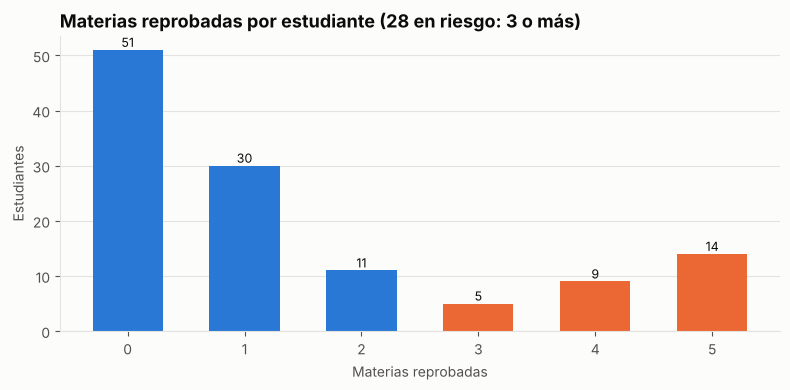

PosixPath('graficos/4_estudiantes_en_riesgo.png')

In [13]:
resultado_4 = materias_reprobadas_por_estudiante(bd)
display(resultado_4.head(10))
graficar_riesgo(resultado_4)

## 8. Consulta 5 – Asistencia por parcial

Usa la colección `asistencia` (4 560 registros). `$cond` con `$ne` cuenta
como asistencia todo lo que no sea `AUSENTE`.

In [14]:
def asistencia_por_parcial(bd):
    """Consulta 5: porcentaje de asistencia y atrasos en cada parcial.

    El atraso cuenta como asistencia, igual que en el calculo de aprobacion.

    Args:
        bd: Base de datos de MongoDB.

    Returns:
        DataFrame con una fila por parcial.
    """
    pipeline = [
        {"$group": {
            "_id": "$parcial",
            "registros": {"$sum": 1},
            "asistencias": {"$sum": {
                "$cond": [{"$ne": ["$estado", "AUSENTE"]}, 1, 0]}},
            "atrasos": {"$sum": {
                "$cond": [{"$eq": ["$estado", "ATRASO"]}, 1, 0]}},
        }},
        {"$sort": {"_id": 1}},
    ]
    datos = consultar(bd, "asistencia", pipeline)
    datos = datos.rename(columns={"_id": "parcial"})
    datos["pct_asistencia"] = datos["asistencias"] / datos["registros"] * 100
    columnas = ["parcial", "registros", "atrasos", "pct_asistencia"]
    return datos[columnas].round(1)


def graficar_asistencia(datos):
    """Linea con el % de asistencia por parcial y el umbral del 70 %.

    Args:
        datos: Resultado de ``asistencia_por_parcial``.

    Returns:
        Ruta del PNG generado.
    """
    etiquetas = [f"Parcial {p}" for p in datos["parcial"]]
    figura, eje = plt.subplots(figsize=(8, 4))
    eje.plot(etiquetas, datos["pct_asistencia"], color=COLOR_PRINCIPAL,
             linewidth=2, marker="o", markersize=8)
    for x, y in zip(etiquetas, datos["pct_asistencia"]):
        eje.annotate(f"{y:.1f} %", (x, y), textcoords="offset points",
                     xytext=(0, 10), ha="center", color=TINTA_PRIMARIA)
    eje.axhline(ASISTENCIA_MINIMA, color=COLOR_REFERENCIA, linestyle="--",
                linewidth=1)
    eje.text(0, ASISTENCIA_MINIMA + 1, "Mínimo 70 %",
             color=TINTA_SECUNDARIA, fontsize=9)
    eje.set_ylim(60, 100)
    eje.set_ylabel("Asistencia (%)")
    eje.grid(axis="x", visible=False)
    eje.set_title("Asistencia promedio por parcial")
    return guardar(figura, "5_asistencia_por_parcial")

,parcial,registros,atrasos,pct_asistencia
0,1,1440,96,84.0
1,2,1440,96,86.7
2,3,1680,95,85.4


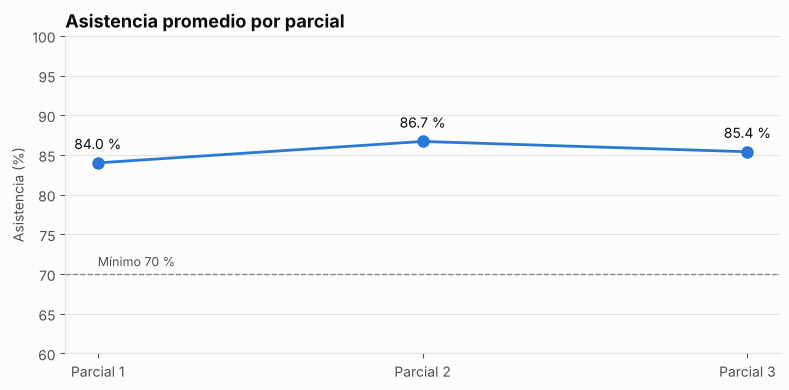

PosixPath('graficos/5_asistencia_por_parcial.png')

In [15]:
resultado_5 = asistencia_por_parcial(bd)
display(resultado_5.head(10))
graficar_asistencia(resultado_5)

## 9. Consulta 6 – Asistencia frente a nota final

Consulta simple con `find` y proyección. El cuadrante superior derecho del
gráfico es la zona de aprobación.

In [16]:
def nota_vs_asistencia(bd):
    """Consulta 6: nota final y asistencia de cada registro.

    Args:
        bd: Base de datos de MongoDB.

    Returns:
        DataFrame con ``porcentaje_asistencia``, ``nota_final`` y ``estado``.
    """
    proyeccion = {"_id": 0, "porcentaje_asistencia": 1,
                  "nota_final": 1, "estado": 1}
    return pd.DataFrame(list(bd.calificaciones.find({}, proyeccion)))


def graficar_dispersion(datos):
    """Dispersion de asistencia contra nota final, coloreada por estado.

    Las lineas punteadas marcan los dos umbrales de aprobacion, asi que el
    cuadrante superior derecho es la zona de aprobacion.

    Args:
        datos: Resultado de ``nota_vs_asistencia``.

    Returns:
        Ruta del PNG generado.
    """
    figura, eje = plt.subplots(figsize=(8, 5))
    for estado, color in (("APROBADO", COLOR_PRINCIPAL),
                          ("REPROBADO", COLOR_CONTRASTE)):
        grupo = datos[datos["estado"] == estado]
        eje.scatter(grupo["porcentaje_asistencia"], grupo["nota_final"],
                    s=22, color=color, alpha=0.7, edgecolors=FONDO,
                    linewidths=0.6, label=f"{estado.capitalize()} "
                    f"({len(grupo)})")
    eje.axhline(NOTA_MINIMA, color=COLOR_REFERENCIA, linestyle="--",
                linewidth=1)
    eje.axvline(ASISTENCIA_MINIMA, color=COLOR_REFERENCIA, linestyle="--",
                linewidth=1)
    eje.set_xlabel("Asistencia (%)")
    eje.set_ylabel("Nota final (sobre 10)")
    eje.legend(loc="lower right")
    eje.set_title("Asistencia vs. nota final (600 registros)")
    return guardar(figura, "6_asistencia_vs_nota")

,nota_final,porcentaje_asistencia,estado
0,8.34,71.43,APROBADO
1,7.07,87.50,APROBADO
2,6.00,100.00,REPROBADO
3,7.49,87.50,APROBADO
4,9.10,100.00,APROBADO
5,4.55,71.43,REPROBADO
6,5.34,75.00,REPROBADO
7,4.11,57.14,REPROBADO
8,5.20,62.50,REPROBADO
9,5.58,62.50,REPROBADO


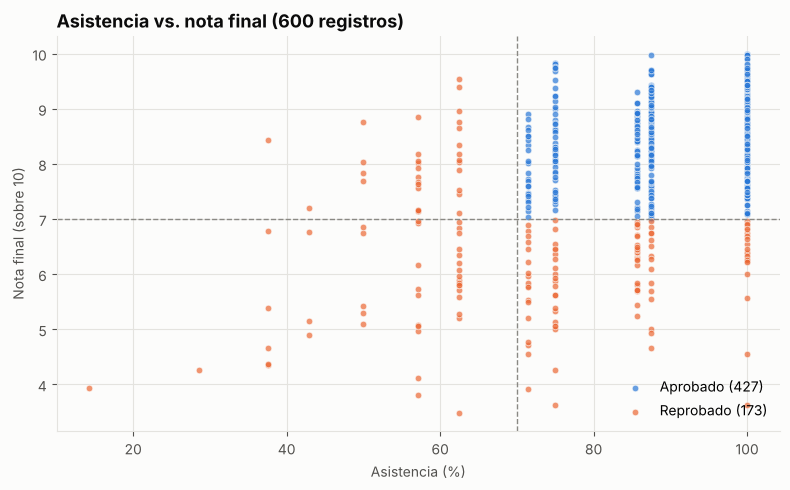

PosixPath('graficos/6_asistencia_vs_nota.png')

In [17]:
resultado_6 = nota_vs_asistencia(bd)
display(resultado_6.head(10))
graficar_dispersion(resultado_6)

## 10. Reporte de indicadores

Resumen de los resultados principales, calculado con los datos ya
consultados.

In [18]:
calificaciones = pd.DataFrame(list(bd.calificaciones.find(
    {}, {"_id": 0, "nota_final": 1, "porcentaje_asistencia": 1,
         "estado": 1})))
aprobados = (calificaciones["estado"] == "APROBADO").sum()
en_riesgo = resultado_4.loc[resultado_4["materias_reprobadas"] >= 3,
                            "estudiantes"].sum()
critica = resultado_1.iloc[0]

print("=" * 60)
print("   REPORTE DE RENDIMIENTO ACADEMICO (MONGODB)")
print("=" * 60)
print(f"Estudiantes analizados:      {bd.estudiantes.count_documents({})}")
print(f"Registros de calificacion:   {len(calificaciones)}")
print(f"Promedio general:            "
      f"{calificaciones['nota_final'].mean():.2f}")
print(f"Asistencia promedio:         "
      f"{calificaciones['porcentaje_asistencia'].mean():.1f} %")
print(f"Aprobacion general:          "
      f"{aprobados / len(calificaciones) * 100:.1f} %")
print(f"Materia critica:             {critica['materia']} "
      f"({critica['tasa_aprobacion']:.1f} % aprueba)")
print(f"Estudiantes en riesgo (3+):  {en_riesgo}")
print("=" * 60)

   REPORTE DE RENDIMIENTO ACADEMICO (MONGODB)
Estudiantes analizados:      120
Registros de calificacion:   600
Promedio general:            7.83
Asistencia promedio:         85.4 %
Aprobacion general:          71.2 %
Materia critica:             Matematicas para IA (61.7 % aprueba)
Estudiantes en riesgo (3+):  28


## 11. Recomendaciones

1. **Nivelar Matemáticas para IA**, la materia con menor tasa de aprobación.
2. **Alerta temprana** cuando la asistencia de un estudiante baje del 80 %,
   antes del límite del 70 %.
3. **Consejería** para los estudiantes en riesgo, con prioridad para quienes
   reprobaron todas las materias.
4. **Repetir el análisis con datos reales** para confirmar si el hallazgo
   sobre los estudiantes que trabajan se mantiene.